In [1]:
import numpy as np

data = [-50, -2, 8, 19, 29, 33, 34, 49, 50, 53, 59, 64, 87, 99, 1456]

# 1. Calculate Q1 (25th percentile), Q3 (75th percentile), and IQR
q1 = np.percentile(data, 25)
q3 = np.percentile(data, 75)
iqr = q3 - q1

# 2. Compute lower and upper outlier fences
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# 3. Separate outliers from inliers
outliers = [x for x in data if x < lower_bound or x > upper_bound]
inliers = [x for x in data if lower_bound <= x <= upper_bound]

print(f"Q1: {q1}")
print(f"Q3: {q3}")
print(f"IQR: {iqr}")
print(f"Lower Bound: {lower_bound}")
print(f"Upper Bound: {upper_bound}")
print(f"Outliers: {outliers}")
print(f"Inliers: {inliers}")

Q1: 24.0
Q3: 61.5
IQR: 37.5
Lower Bound: -32.25
Upper Bound: 117.75
Outliers: [-50, 1456]
Inliers: [-2, 8, 19, 29, 33, 34, 49, 50, 53, 59, 64, 87, 99]


Q1: 24.0
Q3: 61.5
IQR: 37.5
Lower Bound: -32.25
Upper Bound: 117.75
Outliers: [-50, 1456]
Inliers: [-2, 8, 19, 29, 33, 34, 49, 50, 53, 59, 64, 87, 99]


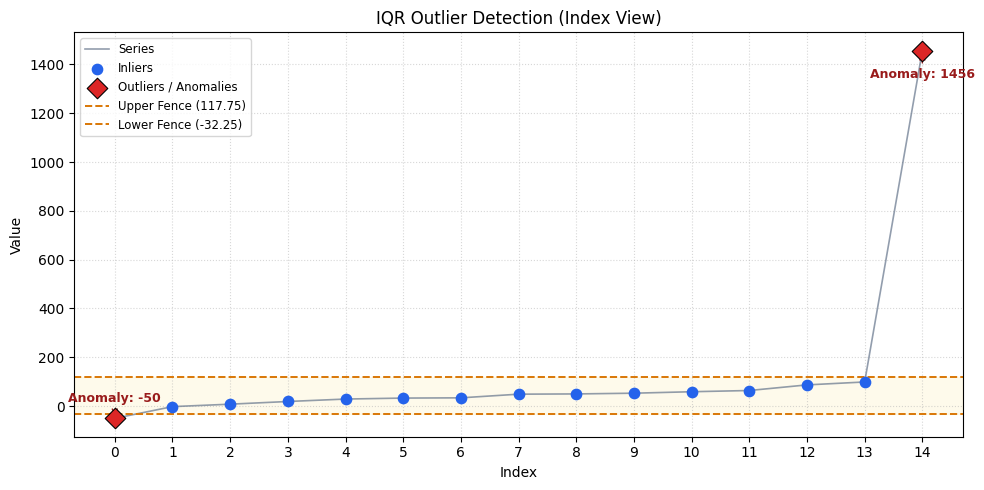

In [2]:
import matplotlib.pyplot as plt
import numpy as np


def find_outliers_iqr(values, k=1.5):
    q1, q3 = np.percentile(values, [25, 75])
    iqr = q3 - q1
    lower_bound = q1 - k * iqr
    upper_bound = q3 + k * iqr

    outliers = [x for x in values if x < lower_bound or x > upper_bound]
    inliers = [x for x in values if lower_bound <= x <= upper_bound]

    return {
        "q1": float(q1),
        "q3": float(q3),
        "iqr": float(iqr),
        "lower_bound": float(lower_bound),
        "upper_bound": float(upper_bound),
        "outliers": outliers,
        "inliers": inliers,
    }


data = [-50, -2, 8, 19, 29, 33, 34, 49, 50, 53, 59, 64, 87, 99, 1456]
stats = find_outliers_iqr(data, k=1.5)

print(f"Q1: {stats['q1']}")
print(f"Q3: {stats['q3']}")
print(f"IQR: {stats['iqr']}")
print(f"Lower Bound: {stats['lower_bound']}")
print(f"Upper Bound: {stats['upper_bound']}")
print(f"Outliers: {stats['outliers']}")
print(f"Inliers: {stats['inliers']}")

lower_bound = stats["lower_bound"]
upper_bound = stats["upper_bound"]
indices = np.arange(len(data))
is_outlier = np.array([(x < lower_bound) or (x > upper_bound) for x in data])
inlier_idx = indices[~is_outlier]
inlier_val = np.array(data)[~is_outlier]
outlier_idx = indices[is_outlier]
outlier_val = np.array(data)[is_outlier]

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(indices, data, color="#64748b", linewidth=1.2, linestyle="-", alpha=0.7, label="Series")
ax.scatter(inlier_idx, inlier_val, color="#2563eb", s=55, zorder=3, label="Inliers")
ax.scatter(
    outlier_idx,
    outlier_val,
    color="#dc2626",
    s=110,
    marker="D",
    edgecolors="black",
    linewidth=0.8,
    zorder=4,
    label="Outliers / Anomalies",
)

ax.axhline(upper_bound, color="#d97706", linestyle="--", linewidth=1.4, label=f"Upper Fence ({upper_bound:.2f})")
ax.axhline(lower_bound, color="#d97706", linestyle="--", linewidth=1.4, label=f"Lower Fence ({lower_bound:.2f})")
ax.axhspan(lower_bound, upper_bound, color="#fef3c7", alpha=0.35, zorder=1)

for idx, val in zip(outlier_idx, outlier_val):
    ax.annotate(
        f"Anomaly: {val}",
        xy=(idx, val),
        xytext=(0, 12 if val < 500 else -20),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold",
        color="#991b1b",
        arrowprops=dict(arrowstyle="->", color="#991b1b", lw=1),
    )

ax.set_title("IQR Outlier Detection (Index View)")
ax.set_xlabel("Index")
ax.set_ylabel("Value")
ax.set_xticks(indices)
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.show()